# Source E: Medi-Cal FFS provider list

Exploratory inspection only. Run the code cells from top to bottom with **Shift+Enter**. The source CSVs use Windows-1252 text encoding; the loader below specifies it so names with accented characters can be read.

## 1. Find the data and import pandas

In [2]:
from pathlib import Path
import pandas as pd

relative_partition_dir = Path(
    "data/provider-side/E-mediCal-fee-for-service-enrolled-providers/"
    "zipped_bc_too_big_for_github"
)

repo_root = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / relative_partition_dir).is_dir()
    ),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "Could not find the Source E data from the notebook's current folder: "
        f"{Path.cwd()}. Start Jupyter with the repository folder as its root."
    )

partition_dir = repo_root / relative_partition_dir
print("Source E folder:", partition_dir)

Source E folder: C:\Users\Benjamin Tran\.copilot\repos\IEHP-CEO-Competition\data\provider-side\E-mediCal-fee-for-service-enrolled-providers\zipped_bc_too_big_for_github


## 2. Load the two CSV parts

Blank fields are treated as missing. Literal values such as `N/A` are left as provided in the source.

In [3]:
csv_files = [
    partition_dir / "medi-cal-ffs-provider-listing_10_26_26_PART 1 first 200k line.csv",
    partition_dir / "medi-cal-ffs-provider-listing_10_26_26_PART 2 next 180k line.csv",
]

providers_df = pd.concat(
    [
        pd.read_csv(
            path,
            encoding="cp1252",
            low_memory=False,
            keep_default_na=False,
            na_values=[""],
        )
        for path in csv_files
    ],
    ignore_index=True,
)

print("Loaded both CSV parts into providers_df.")

Loaded both CSV parts into providers_df.


## 3. Dataset overview: shape and columns

In [4]:
print("Shape (rows, columns):", providers_df.shape)
print("\nColumn names:")
print(providers_df.columns.tolist())

Shape (rows, columns): (380896, 47)

Column names:
['Provider_Number', 'NPI', 'NPI_Type', 'Owner_Number', 'Service_Location_Number', 'Legal_Name', 'Enroll_Status_Eff_DT', 'Provider_Taxonomy', 'NEMT_NMT_Provider_Type', 'ANC_Provider_Type', 'FI_Provider_Type_CD', 'FI_Provider_Type', 'Provider_License', 'FI_Provider_Specialty_CD', 'FI_Provider_Specialty', 'Out_of_State_Indicator', 'In_Out_State', 'Address_Attention', 'Address', 'Address2', 'City', 'State', 'ZIP', 'ZIP_4', 'DHCS_County_CD', 'FIPS_County_CD', 'County', 'Phone_Number', 'Medicaid_Patients', 'CHIP_Patients', 'Telehealth_Services', 'Provider_Website', 'Threshold_Languages', 'Other_Languages', 'Acc_Exam_Room', 'Acc_Exterior_Building', 'Acc_Interior_Building', 'Acc_Parking', 'Acc_Restroom', 'Acc_Medical_Equipment', 'Acc_Patient_Areas', 'Acc_Patient_Diagnostic', 'Provider_Source', 'Billing_Provider', 'Latitude', 'Longitude', 'CountyName']


## 4. Data types and first five rows

In [5]:
display(providers_df.dtypes.rename("dtype").to_frame())
display(providers_df.head())

,dtype
Provider_Number,object
NPI,float64
NPI_Type,str
Owner_Number,float64
Service_Location_Number,float64
Legal_Name,str
Enroll_Status_Eff_DT,str
Provider_Taxonomy,str
NEMT_NMT_Provider_Type,str
ANC_Provider_Type,str


,Provider_Number,NPI,NPI_Type,Owner_Number,Service_Location_Number,Legal_Name,Enroll_Status_Eff_DT,Provider_Taxonomy,NEMT_NMT_Provider_Type,ANC_Provider_Type,...,Acc_Parking,Acc_Restroom,Acc_Medical_Equipment,Acc_Patient_Areas,Acc_Patient_Diagnostic,Provider_Source,Billing_Provider,Latitude,Longitude,CountyName
0,1003000639.0,1.003001e+09,Type 1,1.0,1.0,"BENHARASH, PEYMAN MD",1/19/2011 0:00,No Taxonomy Provided,N/A,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,FFS Non-Billing Provider,34.063722,-118.443467,Los Angeles County
1,1003000563.0,1.003001e+09,Type 2,1.0,1.0,"CHUN, RICHARD B D MD INC",4/1/2002 0:00,207RG0100X,N/A,Gastroenterology,...,NaN,NaN,NaN,NaN,NaN,1.0,FFS Billing Provider,38.734427,-121.271995,Placer County
2,1003000563.0,1.003001e+09,Type 2,1.0,1.0,"CHUN, RICHARD B D MD INC",4/1/2002 0:00,207RG0100X,N/A,Gastroenterology,...,NaN,NaN,NaN,NaN,NaN,1.0,FFS Billing Provider,38.734427,-121.271995,Placer County
3,1003001157.0,1.003001e+09,Type 1,1.0,1.0,"KIM, DAVID C MD",7/18/2003 0:00,No Taxonomy Provided,N/A,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,FFS Non-Billing Provider,34.099394,-117.421262,San Bernardino County
4,1003000225.0,1.003000e+09,Type 1,1.0,1.0,"MORGAN, ANNA C A MD",10/15/2008 0:00,No Taxonomy Provided,N/A,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,FFS Non-Billing Provider,37.891776,-122.058050,Contra Costa County


## 5. Missing-value counts

These counts reflect blank CSV fields only; placeholder strings like `N/A` are not counted as missing.

In [6]:
display(
    providers_df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

,missing_count
Provider_Number,8
NPI,57
NPI_Type,57
Owner_Number,8
Service_Location_Number,8
Legal_Name,8
Enroll_Status_Eff_DT,8
Provider_Taxonomy,8
NEMT_NMT_Provider_Type,8
ANC_Provider_Type,123368


## 6. Candidate columns, unique values, and ZIP type

In [7]:
column_candidates = {
    "Provider ID or NPI": ["Provider_Number", "NPI", "NPI_Type"],
    "Provider name": ["Legal_Name"],
    "County": ["County", "CountyName", "DHCS_County_CD", "FIPS_County_CD"],
    "ZIP code": ["ZIP", "ZIP_4"],
    "City": ["City"],
    "Provider type": ["FI_Provider_Type_CD", "FI_Provider_Type", "ANC_Provider_Type"],
    "Specialty": ["FI_Provider_Specialty_CD", "FI_Provider_Specialty"],
}

print("Candidate columns present:")
for label, candidates in column_candidates.items():
    present = [column for column in candidates if column in providers_df.columns]
    print(f"{label}: {present}")

print("\nDataset as of: October 26, 2026 (from datapackage metadata; not a CSV column)")

for label, column in [
    ("County", "County"),
    ("Coordinate-derived county", "CountyName"),
    ("Provider type", "FI_Provider_Type"),
    ("Specialty", "FI_Provider_Specialty"),
]:
    if column in providers_df.columns:
        print(f"\nUnique {label} values ({column}):")
        print(providers_df[column].dropna().unique().tolist())

if "ZIP" in providers_df.columns:
    print("\nZIP pandas dtype:", providers_df["ZIP"].dtype)
    print("ZIP sample values:", providers_df["ZIP"].dropna().head(10).tolist())
    zip_is_text = pd.api.types.is_string_dtype(providers_df["ZIP"])
    print("ZIP is treated as:", "text" if zip_is_text else "non-text / likely numeric")

Candidate columns present:
Provider ID or NPI: ['Provider_Number', 'NPI', 'NPI_Type']
Provider name: ['Legal_Name']
County: ['County', 'CountyName', 'DHCS_County_CD', 'FIPS_County_CD']
ZIP code: ['ZIP', 'ZIP_4']
City: ['City']
Provider type: ['FI_Provider_Type_CD', 'FI_Provider_Type', 'ANC_Provider_Type']
Specialty: ['FI_Provider_Specialty_CD', 'FI_Provider_Specialty']

Dataset as of: October 26, 2026 (from datapackage metadata; not a CSV column)

Unique County values (County):
['Los Angeles', 'Placer', 'San Bernardino', 'Contra Costa', 'N/A', 'Sacramento', 'Imperial', 'Santa Clara', 'Monterey', 'Alameda', 'Orange', 'Ventura', 'Sonoma', 'UNKNOWN', 'Kern', 'Stanislaus', 'Merced', 'San Diego', 'San Mateo', 'Solano', 'Tuolumne', 'San Francisco', 'Fresno', 'Santa Cruz', 'Riverside', 'Nevada', 'El Dorado', 'Tulare', 'Kings', 'Santa Barbara', 'San Joaquin', 'Sutter', 'San Luis Obispo', 'Yolo', 'Marin', 'Shasta', 'Humboldt', 'San Benito', 'Napa', 'Butte', 'Mendocino', 'Mariposa', 'Del Norte',

## Field guide and limitations

Based on the accompanying `datapackage.json` schema:

- `Provider_Number` is the PMF provider identifier and can be either an NPI or a Medi-Cal legacy number. `NPI` is the separate CMS identifier; `NPI_Type` distinguishes individual (Type 1) from organization (Type 2). `Owner_Number` and `Service_Location_Number` identify ownership and service-location records.
- `Legal_Name` is the name reported in the Provider Master File. `Enroll_Status_Eff_DT` is the enrollment effective date, not the snapshot date.
- `FI_Provider_Type_CD` / `FI_Provider_Type` are PMF provider type code/description. `FI_Provider_Specialty_CD` / `FI_Provider_Specialty` are PMF specialty code/description. `Provider_Taxonomy` is PAVE-reported taxonomy; `ANC_Provider_Type` is a mapped network-certification type.
- `Address`, `Address2`, `City`, `State`, `ZIP`, and `ZIP_4` describe the service location. `DHCS_County_CD` and `FIPS_County_CD` are county codes. The schema gives no description for `County`; `CountyName` is explicitly based on latitude/longitude coordinates.
- `Latitude` and `Longitude` are coordinates. `Provider_License` is a reported state license number for specified provider categories; blanks mean license data is unavailable, and a dash may be shown for out-of-state or other providers.
- `Billing_Provider` distinguishes FFS billing from FFS non-billing providers. `Medicaid_Patients` is a reported new-patient acceptance field, with metadata meanings N/F/M/B. It is not inferred here and must not be treated as equivalent to enrollment. `CHIP_Patients` and `Telehealth_Services` are separate reported flags.
- `Out_of_State_Indicator` / `In_Out_State` represent location status. `NEMT_NMT_Provider_Type` describes approved non-emergency or non-medical transportation type. Language and `Acc_*` fields describe reported languages and accessibility features. `Provider_Source` is marked for DHCS internal use in the schema.

The metadata says this is a point-in-time Medi-Cal FFS enrollment dataset as of October 26, 2026. It excludes managed-care providers and dental FFS providers, may contain incomplete or inaccurate records, and may have a 1-2 day quality-assurance lag. The source schema does not define a UIS field; no UIS status should be inferred.

Before interpreting provider-per-member rates, confirm the intended row grain (provider, owner, or service location), the meaning/authority of `County` versus coordinate-derived `CountyName`, and how to handle legacy IDs and missing/literal placeholder values. ZIP codes are geographic identifiers and should remain text; the inspection cell reports the dtype actually loaded. The initial inspection section above does not clean, filter, deduplicate, visualize, or export the source data. The access-analysis section below filters derived working tables by the selected month and region without modifying the source files.

## 7. Access-to-care analysis setup

The competition guide recommends comparing one month of Medi-Cal members by ZIP (Source A) with enrolled FFS providers by service ZIP (Source E), using Source H to identify Riverside and San Bernardino ZIPs. September 2026 is used below as the guide recommends August or September; it is marked preliminary. The crosswalk is the latest copy included here (June 2026). ZIPs crossing county lines are flagged rather than allocated. These steps create analysis-specific tables without changing the source data.

### 7a. Build the Inland Empire ZIP list from Source H

In [ ]:
def normalize_zip(values):
    """Normalize ZIPs in derived analysis columns while retaining them as text."""
    zip_text = values.astype("string").str.strip()
    valid_zip = zip_text.str.fullmatch(r"\d{1,5}", na=False)
    return zip_text.where(valid_zip).str.zfill(5)

crosswalk_path = (
    repo_root
    / "data/provider-side/H-county-zip-crosswalk/ZIP-COUNTY_062026.xlsx"
)
county_zip_df = pd.read_excel(
    crosswalk_path,
    dtype={"zip": "string", "geoid": "string"},
)
county_zip_df["ZIP"] = normalize_zip(county_zip_df["zip"])
county_zip_df["County_GEOID"] = county_zip_df["geoid"].astype("string").str.zfill(5)

ie_counties = {
    "06065": "Riverside",
    "06071": "San Bernardino",
}
county_zip_df["County"] = county_zip_df["County_GEOID"].map(ie_counties)

all_counties_per_zip = (
    county_zip_df.dropna(subset=["ZIP", "County_GEOID"])
    .groupby("ZIP")["County_GEOID"]
    .nunique()
)
ie_zip_map = (
    county_zip_df.loc[
        county_zip_df["County_GEOID"].isin(ie_counties),
        ["ZIP", "County"],
    ]
    .dropna(subset=["ZIP"])
    .groupby("ZIP", as_index=False)
    .agg(IE_Counties=("County", lambda values: ", ".join(sorted(set(values)))))
)
ie_zip_map["Crosswalk_County_Count"] = (
    ie_zip_map["ZIP"].map(all_counties_per_zip).fillna(0).astype(int)
)
ie_zip_map["Crosses_County_Boundary"] = ie_zip_map["Crosswalk_County_Count"] > 1
ie_zips = set(ie_zip_map["ZIP"])

print("Inland Empire ZIPs in the June 2026 crosswalk:", len(ie_zips))
print(
    "IE ZIPs linked to more than one county:",
    int(ie_zip_map["Crosses_County_Boundary"].sum()),
)
display(ie_zip_map.sort_values("ZIP").head(15))

### 7b. Prepare September 2026 Medi-Cal member counts (Source A)

Source A includes a Total row as well as male and female rows, so this cell sums the two sex-specific rows and excludes Total to avoid double counting. Suppressed/blank counts remain missing rather than being treated as zero.

In [ ]:
members_path = (
    repo_root
    / "data/demand-side/A-medical-eligible-counts-by-ZIP/"
    "calendar-years-2020-to-the-most-recent-reportable-month.csv"
)
members_raw_df = pd.read_csv(
    members_path,
    encoding="cp1252",
    dtype={"Zip Code": "string", "Total Eligibles": "string"},
    keep_default_na=False,
)

selected_month = "2026-09"
month_rows = members_raw_df.loc[
    (members_raw_df["Month of Eligibility"] == selected_month)
    & (members_raw_df["Sex"].isin(["Female", "Male"]))
].copy()
month_rows["ZIP"] = normalize_zip(month_rows["Zip Code"])
month_rows["Eligible_Count"] = pd.to_numeric(
    month_rows["Total Eligibles"].str.replace(",", "", regex=False),
    errors="coerce",
)
month_rows = month_rows.loc[month_rows["ZIP"].isin(ie_zips)].copy()

sex_counts_by_zip = (
    month_rows.groupby(["ZIP", "Sex"])["Eligible_Count"]
    .sum(min_count=1)
    .unstack("Sex")
)
for sex in ["Female", "Male"]:
    if sex not in sex_counts_by_zip.columns:
        sex_counts_by_zip[sex] = pd.NA
sex_counts_by_zip["Medi-Cal Members"] = sex_counts_by_zip[["Female", "Male"]].sum(
    axis=1,
    min_count=2,
)

members_by_zip_ie = (
    ie_zip_map.set_index("ZIP")
    .join(sex_counts_by_zip[["Female", "Male", "Medi-Cal Members"]])
    .reset_index()
    .sort_values("ZIP")
)

print("Selected month:", selected_month)
print("Reported status:", sorted(month_rows["Status"].dropna().unique().tolist()))
print("Date of data:", sorted(month_rows["Date of Data"].dropna().unique().tolist()))
print("Rows for selected month and IE ZIPs:", len(month_rows))
print(
    "IE ZIP sex rows with an annotation code:",
    int(month_rows["Annotation Code"].str.strip().ne("").sum()),
)
print("ZIP rows with a missing sex-specific count:", int(sex_counts_by_zip[["Female", "Male"]].isna().any(axis=1).sum()))
display(members_by_zip_ie)

### 7c. Inspect Source E provider types and service locations

This inventory uses the provider-type and specialty descriptions reported by DHCS. It does not yet assign primary-care, specialty, or mental-health groupings; the challenge guide does not prescribe exact code lists. Multiple service-location records are audited but not removed.

In [ ]:
provider_columns = [
    "Provider_Number",
    "NPI",
    "NPI_Type",
    "Owner_Number",
    "Service_Location_Number",
    "FI_Provider_Type_CD",
    "FI_Provider_Type",
    "FI_Provider_Specialty_CD",
    "FI_Provider_Specialty",
    "ZIP",
    "City",
    "County",
    "Billing_Provider",
]
identifier_dtypes = {column: "string" for column in provider_columns}
provider_analysis_df = pd.concat(
    [
        pd.read_csv(
            path,
            usecols=provider_columns,
            dtype=identifier_dtypes,
            encoding="cp1252",
            keep_default_na=False,
            na_values=[""],
        )
        for path in csv_files
    ],
    ignore_index=True,
)
provider_analysis_df["ZIP"] = normalize_zip(provider_analysis_df["ZIP"])
providers_in_ie_zip_df = provider_analysis_df.loc[
    provider_analysis_df["ZIP"].isin(ie_zips)
].copy()

provider_type_inventory = (
    providers_in_ie_zip_df.groupby(
        ["FI_Provider_Type_CD", "FI_Provider_Type"],
        dropna=False,
    )
    .agg(
        source_rows=("Provider_Number", "size"),
        unique_provider_numbers=("Provider_Number", "nunique"),
        unique_npis=("NPI", "nunique"),
    )
    .reset_index()
    .sort_values("unique_provider_numbers", ascending=False)
)
specialty_inventory = (
    providers_in_ie_zip_df.groupby(
        ["FI_Provider_Specialty_CD", "FI_Provider_Specialty"],
        dropna=False,
    )
    .agg(
        source_rows=("Provider_Number", "size"),
        unique_provider_numbers=("Provider_Number", "nunique"),
    )
    .reset_index()
    .sort_values("unique_provider_numbers", ascending=False)
)

provider_type_by_zip = (
    providers_in_ie_zip_df.groupby(
        ["ZIP", "FI_Provider_Type_CD", "FI_Provider_Type"],
        dropna=False,
    )["Provider_Number"]
    .nunique()
    .rename("unique_provider_numbers")
    .reset_index()
)

provider_locations_by_id = (
    providers_in_ie_zip_df.dropna(subset=["Provider_Number"])
    .groupby("Provider_Number")
    .agg(
        service_locations=("Service_Location_Number", "nunique"),
        service_zips=("ZIP", "nunique"),
        source_rows=("Provider_Number", "size"),
    )
)
repeated_provider_ids = provider_locations_by_id.loc[
    (provider_locations_by_id["service_locations"] > 1)
    | (provider_locations_by_id["service_zips"] > 1)
]

print("Source E records in IE ZIPs:", len(providers_in_ie_zip_df))
print(
    "Unique provider numbers:",
    providers_in_ie_zip_df["Provider_Number"].nunique(),
)
print("Provider types reported in IE ZIPs:")
display(provider_type_inventory)
print("Specialties reported in IE ZIPs:")
display(specialty_inventory)
print("Provider-number counts by ZIP and reported type (first 30 rows):")
display(provider_type_by_zip.sort_values(["ZIP", "FI_Provider_Type"]).head(30))
print(
    "Provider numbers with multiple locations or ZIPs:",
    len(repeated_provider_ids),
)
display(
    repeated_provider_ids.sort_values(
        ["service_zips", "service_locations"],
        ascending=False,
    ).head(20)
)


### Interpretation before calculating rates

The member ZIP counts are preliminary and suppressed cells remain missing; neither should be silently interpreted as a complete count. Source E enrollment does not mean a provider is accepting new FFS patients, and the guide recommends treating it as a best-case supply estimate. The crosswalk flags ZIPs with more than one county relationship; no fractional allocation is applied here. Source E excludes dental providers, which the guide says to analyze separately with Source F.

Before calculating provider-per-1,000-member ratios, choose which reported provider types/specialties to include in primary care, key specialty, and mental-health groups, and confirm whether `Provider_Number` is the desired counting unit or whether provider NPIs / service locations should be counted differently. The inventory above exposes the raw types and repeated-location issue without deduplicating the source.

## 8. Primary-care access analysis (supports Recommendation 2)

This section is self-contained: it can be run on its own after the kernel starts.

**Question:** which Inland Empire ZIPs have the most estimated transitioning members per listed FFS primary-care provider?

**Definitions (team choices, change them in the next cell)**
- **Demand:** Source A Medi-Cal members by ZIP, September 2026 (preliminary). Female + Male, falling back to the published Total when a sex row is suppressed. Suppressed ZIPs stay missing, never zero.
- **Region:** ZIPs with at least half their residential addresses in Riverside or San Bernardino (Source H, June 2026). ZIPs with under 95% in one county are flagged as split.
- **Supply (core):** unique individual (Type 1) physicians in Family Practice, General Practice, Internal Medicine, Pediatrics or Geriatrics, counted once per ZIP. Physician groups are left out to avoid double counting their members.
- **Estimated transitioning members:** IEHP's estimate of 119,600 (Q&A email) spread across ZIPs in proportion to Medi-Cal members. **This allocation is an assumption.** County UIS counts do not say which ZIPs members live in, and Source A is all Medi-Cal, not UIS.
- **Transition Provider Pressure (TPP):** estimated transitioning members divided by listed FFS primary-care providers. It flags places to investigate. It does not prove how many patients a provider can take, and Source E enrollment does not show who accepts new patients.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPORT_MONTH = "2026-09"
IEHP_TRANSITION_EST = 119_600                                 # Q&A email, from IEHP
UIS_JUNE_2026 = {"Riverside": 88_717, "San Bernardino": 83_742}  # Q&A email, DHCS June 2026
MIN_ZIP_MEMBERS = 1_000   # TEAM ASSUMPTION: smaller ZIPs are not ranked
PCP_SPECIALTY_CODES = {"8", "1", "41", "40", "38"}  # Family, General Practice, Internal Med, Pediatrics, Geriatrics

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/provider-side/H-county-zip-crosswalk").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("Start Jupyter from the repository folder.")
ACCESS_OUT = root / "analysis_outputs/access"
ACCESS_OUT.mkdir(parents=True, exist_ok=True)

def zip5(values):
    text = values.astype("string").str.strip().str[:5]
    return text.where(text.str.fullmatch(r"\d{5}", na=False))

def to_num(values):
    return pd.to_numeric(values.astype("string").str.replace(",", "").str.strip(), errors="coerce")

# Region ZIPs from Source H
xw = pd.read_excel(root / "data/provider-side/H-county-zip-crosswalk/ZIP-COUNTY_062026.xlsx", dtype="string")
xw["ZIP"] = zip5(xw["zip"])
xw["res_ratio"] = pd.to_numeric(xw["res_ratio"])
xw["County"] = xw["geoid"].str.zfill(5).map({"06065": "Riverside", "06071": "San Bernardino"})
share = xw[xw["County"].notna()].pivot_table(index="ZIP", columns="County", values="res_ratio", aggfunc="sum", fill_value=0)
zip_map = pd.DataFrame({"IE_Share": share.sum(axis=1), "Main_County": share.idxmax(axis=1), "Main_County_Share": share.max(axis=1)})
zip_map = zip_map[zip_map["IE_Share"] >= 0.5].copy()
zip_map["Split_ZIP"] = zip_map["Main_County_Share"] < 0.95

# Demand: Source A
a = pd.read_csv(
    root / "data/demand-side/A-medical-eligible-counts-by-ZIP/calendar-years-2020-to-the-most-recent-reportable-month.csv",
    dtype="string", encoding="cp1252", keep_default_na=False,
)
a = a[a["Month of Eligibility"].eq(REPORT_MONTH)].copy()
a["ZIP"] = zip5(a["Zip Code"])
a["N"] = to_num(a["Total Eligibles"])
sex = a.dropna(subset=["ZIP"]).pivot(index="ZIP", columns="Sex", values="N")
members = sex[["Female", "Male"]].sum(axis=1, min_count=2).fillna(sex["Total"]).rename("Medi-Cal members")

# Supply: Source E
prov_cols = ["Provider_Number", "NPI", "NPI_Type", "Service_Location_Number", "FI_Provider_Type_CD",
             "FI_Provider_Specialty_CD", "ZIP", "Medicaid_Patients"]
e_dir = root / "data/provider-side/E-mediCal-fee-for-service-enrolled-providers/zipped_bc_too_big_for_github"
prov = pd.concat(
    [pd.read_csv(f, usecols=prov_cols, dtype="string", encoding="cp1252", keep_default_na=False, na_values=[""])
     for f in sorted(e_dir.glob("*.csv"))],
    ignore_index=True,
)
prov["ZIP"] = zip5(prov["ZIP"])
prov["ID"] = prov["NPI"].str.replace(r"\.0$", "", regex=True).fillna(prov["Provider_Number"])
indiv = prov["NPI_Type"].eq("Type 1")
type_cd, spec_cd = prov["FI_Provider_Type_CD"], prov["FI_Provider_Specialty_CD"]
core = prov[indiv & type_cd.eq("26") & spec_cd.isin(PCP_SPECIALTY_CODES)]
nurse_prac = prov[indiv & type_cd.eq("7")]
clinics = prov[type_cd.eq("35")]   # FFS rural health clinics / FQHCs, counted by service location
not_accepting = prov["Medicaid_Patients"].isin(["N", "M"])

def per_zip(frame, key):
    f = frame.assign(_k=key.loc[frame.index]).dropna(subset=["ZIP", "_k"])
    return f.groupby("ZIP")["_k"].nunique()

loc_key = prov["Provider_Number"].fillna("") + "|" + prov["Service_Location_Number"].fillna("")
variants = {
    "PCP core": per_zip(core, prov["ID"]),
    "PCP core, minus reported N/M": per_zip(core[~not_accepting.loc[core.index]], prov["ID"]),
    "PCP core + nurse practitioners": per_zip(pd.concat([core, nurse_prac]), prov["ID"]),
    "PCP core + NPs + clinic locations": per_zip(pd.concat([core, nurse_prac]), prov["ID"]).add(
        per_zip(clinics, loc_key), fill_value=0),
}

access = zip_map.join(members, how="left")
for name, counts in variants.items():
    access[name] = counts.reindex(access.index).fillna(0).astype(int)
access["Demand_Missing"] = access["Medi-Cal members"].isna()

county_target = {c: IEHP_TRANSITION_EST * v / sum(UIS_JUNE_2026.values()) for c, v in UIS_JUNE_2026.items()}
visible = access["Medi-Cal members"]
access["Est_Transition_A"] = visible / visible.sum() * IEHP_TRANSITION_EST
county_total = visible.groupby(access["Main_County"]).transform("sum")
access["Est_Transition_B"] = visible / county_total * access["Main_County"].map(county_target)

# Source D: IEHP Medi-Cal enrollment, for scenario context
d = pd.read_csv(
    root / "data/demand-side/D-mediCal-managed-care-enrollment/open-data-portal-managed-care-enrollment-count-september-2026.csv",
    dtype="string", encoding="utf-8-sig", keep_default_na=False,
)
d.columns = d.columns.str.strip()
d["Count"] = to_num(d["Count of Enrollees"])
is_iehp = d["Plan Name"].str.startswith("Inland Emp") & ~d["Plan Name"].str.contains("CCI|CMC")
source_d_total = int(d.loc[is_iehp & d["Enrollment Month"].eq(REPORT_MONTH), "Count"].sum())

print(f"Region ZIPs (Source H, at least half in the two counties): {len(access)}; split ZIPs: {int(access['Split_ZIP'].sum())}")
print(f"ZIPs with a usable September 2026 member count: {int((~access['Demand_Missing']).sum())}; suppressed/missing: {int(access['Demand_Missing'].sum())}")
print(f"Medi-Cal members in usable ZIPs: {visible.sum():,.0f} (visible counts only, may understate)")
print(f"Source D IEHP enrollment, {REPORT_MONTH}: {source_d_total:,}")
print("\nListed FFS primary-care providers in region ZIPs:")
print(access[list(variants)].sum().astype(int).to_string())
print("\nZIPs with zero listed core PCPs:", int(access["PCP core"].eq(0).sum()))

Region ZIPs (Source H, at least half in the two counties): 201; split ZIPs: 1
ZIPs with a usable September 2026 member count: 181; suppressed/missing: 20
Medi-Cal members in usable ZIPs: 1,807,977 (visible counts only, may understate)
Source D IEHP enrollment, 2026-09: 1,363,303

Listed FFS primary-care providers in region ZIPs:
PCP core                             4225
PCP core, minus reported N/M         4224
PCP core + nurse practitioners       5909
PCP core + NPs + clinic locations    6073

ZIPs with zero listed core PCPs: 105


ZIPs ranked (at least 1,000 Medi-Cal members): 126; of these, no listed core PCP: 34
Regional median: 0.41 listed PCPs per 1,000 Medi-Cal members; median TPP 72 estimated transitioning members per PCP



,City,Main_County,Medi-Cal members,Est_Transition_A,PCPs,TPP,Per_1000_Medi-Cal
ZIP,,,,,,,
92240,DESERT HOT SPRINGS,Riverside,24138.0,1596.76,0,none listed,0.0
92551,MORENO VALLEY,Riverside,15561.0,1029.38,0,none listed,0.0
92880,EASTVALE,Riverside,14003.0,926.32,0,none listed,0.0
92274,THERMAL,Riverside,12624.0,835.09,0,none listed,0.0
92596,WINCHESTER,Riverside,10225.0,676.4,0,none listed,0.0
92582,SAN JACINTO,Riverside,10129.0,670.05,0,none listed,0.0
92344,HESPERIA,San Bernardino,9839.0,650.86,0,none listed,0.0
92254,MECCA,Riverside,9672.0,639.82,0,none listed,0.0
92532,LAKE ELSINORE,Riverside,8557.0,566.06,0,none listed,0.0


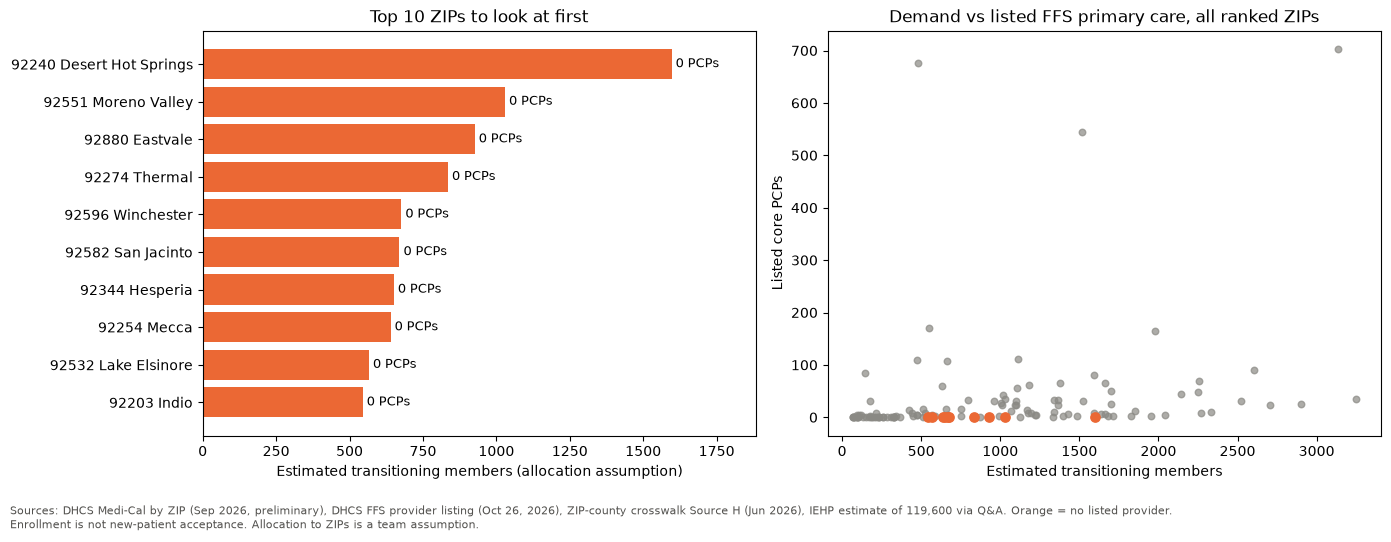

In [4]:
def rank_zips(df, est_col, pcp_col, min_members=MIN_ZIP_MEMBERS):
    """Ranked ZIPs: no-listed-PCP ZIPs first (by demand), then by members per listed PCP."""
    r = df[df["Medi-Cal members"] >= min_members].copy()
    r["PCPs"] = r[pcp_col]
    r["TPP"] = r[est_col] / r["PCPs"].replace(0, np.nan)
    r["Score"] = r["TPP"].fillna(np.inf)
    r["Per_1000_Medi-Cal"] = r["PCPs"] / r["Medi-Cal members"] * 1000
    r = r.sort_values(["Score", est_col], ascending=False)
    r["Rank"] = np.arange(1, len(r) + 1)
    return r

ranked = rank_zips(access, "Est_Transition_A", "PCP core")
cities = xw.dropna(subset=["ZIP"]).drop_duplicates("ZIP").set_index("ZIP")["city"]
ranked["City"] = ranked.index.map(cities)

show_cols = ["City", "Main_County", "Medi-Cal members", "Est_Transition_A", "PCPs", "TPP", "Per_1000_Medi-Cal"]
print(f"ZIPs ranked (at least {MIN_ZIP_MEMBERS:,} Medi-Cal members): {len(ranked)}; of these, no listed core PCP: {int(ranked['PCPs'].eq(0).sum())}")
print(f"Regional median: {ranked['Per_1000_Medi-Cal'].median():.2f} listed PCPs per 1,000 Medi-Cal members; "
      f"median TPP {ranked['TPP'].median():,.0f} estimated transitioning members per PCP\n")
top10 = ranked.head(10)
display(top10[show_cols].assign(TPP=top10["TPP"].astype(object).where(top10["TPP"].notna(), "none listed")).round(2))
ranked.to_csv(ACCESS_OUT / "zip_access_ranking.csv")
access.to_csv(ACCESS_OUT / "zip_access_table_all.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot = ranked.head(10).iloc[::-1]
labels = [f"{z} {c.title()}" for z, c in zip(plot.index, plot["City"])]
axes[0].barh(labels, plot["Est_Transition_A"], color=np.where(plot["PCPs"].eq(0), "#eb6834", "#2a78d6"))
for y, (n, p) in enumerate(zip(plot["Est_Transition_A"], plot["PCPs"])):
    axes[0].text(n, y, f" {p} PCPs", va="center", fontsize=9)
axes[0].set(title="Top 10 ZIPs to look at first", xlabel="Estimated transitioning members (allocation assumption)")
axes[0].margins(x=0.18)

axes[1].scatter(ranked["Est_Transition_A"], ranked["PCPs"], s=22, color="#8a8984", alpha=0.7)
axes[1].scatter(top10["Est_Transition_A"], top10["PCPs"], s=45, color="#eb6834")
axes[1].set(title="Demand vs listed FFS primary care, all ranked ZIPs",
            xlabel="Estimated transitioning members", ylabel="Listed core PCPs")
fig.text(0.01, -0.02, "Sources: DHCS Medi-Cal by ZIP (Sep 2026, preliminary), DHCS FFS provider listing (Oct 26, 2026), ZIP-county crosswalk Source H (Jun 2026), "
         "IEHP estimate of 119,600 via Q&A. Orange = no listed provider.\nEnrollment is not new-patient acceptance. Allocation to ZIPs is a team assumption.",
         fontsize=8, color="#52514e", va="top")
fig.tight_layout()
fig.savefig(ACCESS_OUT / "top10_and_scatter.png", dpi=180, bbox_inches="tight")
plt.show()

### 8a. Does the ranking hold up?

Each row re-ranks ZIPs under a different provider definition and a different way of spreading the 119,600 across ZIPs. Overlap is how many of the baseline top 10 stay in the top 10. A scale change (10%, 14%, 18% of Source D, or 119,600) cannot reorder ZIPs under the proportional allocation, so only magnitudes are shown for scale.

In [9]:
baseline_top10 = set(ranked.head(10).index)
baseline_rank = ranked["Rank"]
allocations = {"A: proportional to ZIP Medi-Cal": "Est_Transition_A", "B: county UIS-weighted": "Est_Transition_B"}

rows = []
for alloc_label, est_col in allocations.items():
    for pcp_col in variants:
        r = rank_zips(access, est_col, pcp_col)
        both = r.index.intersection(baseline_rank.index)
        rho = spearmanr(baseline_rank.loc[both], r.loc[both, "Rank"]).statistic
        rows.append({
            "Allocation": alloc_label, "Provider definition": pcp_col,
            "Top-10 overlap with baseline": len(baseline_top10 & set(r.head(10).index)),
            "ZIPs with no listed PCP": int(r["PCPs"].eq(0).sum()),
            "Rank correlation with baseline": round(rho, 2),
            "Top 3 ZIPs": ", ".join(r.head(3).index),
        })
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(ACCESS_OUT / "ranking_sensitivity.csv", index=False)
display(sensitivity)

always_top10 = baseline_top10.copy()
for alloc_label, est_col in allocations.items():
    for pcp_col in variants:
        always_top10 &= set(rank_zips(access, est_col, pcp_col).head(10).index)
print("ZIPs in the top 10 under every definition and allocation tested:")
display(ranked.loc[sorted(always_top10), ["City", "Main_County", "Medi-Cal members", "PCPs"]])

# Scale scenarios under allocation A: magnitudes change, ordering does not.
scale = pd.DataFrame({
    label: {
        "Transitioning members": total,
        "Top-10 ZIP total": total * ranked.head(10)["Medi-Cal members"].sum() / access["Medi-Cal members"].sum(),
    }
    for label, total in {
        "10% of Source D": source_d_total * 0.10, "14.3% of Source D": source_d_total * 0.143,
        "18% of Source D": source_d_total * 0.18, "IEHP estimate (Q&A)": IEHP_TRANSITION_EST,
    }.items()
}).T.round(0).astype(int)
scale["As % of Source D"] = (scale["Transitioning members"] / source_d_total * 100).round(1)
scale.to_csv(ACCESS_OUT / "scale_scenarios.csv")
display(scale)

,Allocation,Provider definition,Top-10 overlap with baseline,ZIPs with no listed PCP,Rank correlation with baseline,Top 3 ZIPs
0,A: proportional to ZIP Medi-Cal,PCP core,10,34,1.00,"92240, 92551, 92880"
1,A: proportional to ZIP Medi-Cal,"PCP core, minus reported N/M",10,34,1.00,"92240, 92551, 92880"
2,A: proportional to ZIP Medi-Cal,PCP core + nurse practitioners,4,19,0.89,"92274, 92596, 92582"
3,A: proportional to ZIP Medi-Cal,PCP core + NPs + clinic locations,3,15,0.88,"92596, 92582, 92532"
4,B: county UIS-weighted,PCP core,10,34,1.00,"92240, 92551, 92880"
5,B: county UIS-weighted,"PCP core, minus reported N/M",10,34,1.00,"92240, 92551, 92880"
6,B: county UIS-weighted,PCP core + nurse practitioners,4,19,0.89,"92274, 92596, 92582"
7,B: county UIS-weighted,PCP core + NPs + clinic locations,3,15,0.88,"92596, 92582, 92532"


ZIPs in the top 10 under every definition and allocation tested:


,City,Main_County,Medi-Cal members,PCPs
ZIP,,,,
92532,LAKE ELSINORE,Riverside,8557.0,0
92582,SAN JACINTO,Riverside,10129.0,0
92596,WINCHESTER,Riverside,10225.0,0


,Transitioning members,Top-10 ZIP total,As % of Source D
10% of Source D,136330,9274,10.0
14.3% of Source D,194952,13261,14.3
18% of Source D,245395,16693,18.0
IEHP estimate (Q&A),119600,8136,8.8


### 8b. Sizing the outreach: how many providers would close the gap?

**Provider conversion what-if.** If IEHP helped more primary-care providers enroll in FFS in the top ZIPs, how far would pressure fall? The target is the regional median TPP among ZIPs that already have a listed provider (a team benchmark, not a standard). These are planning numbers: an enrolled provider may still not take new patients.

**High-confidence gaps.** ZIPs with no listed provider even under the broadest definition (core physicians, nurse practitioners and FFS clinic locations) are the safest places to start verification.

In [6]:
target_tpp = ranked["TPP"].median()
conv = ranked.head(10)[["City", "Main_County", "Est_Transition_A", "PCPs"]].copy()
for k in (1, 3, 5):
    conv[f"TPP with +{k}"] = (conv["Est_Transition_A"] / (conv["PCPs"] + k)).round(0)
conv["Providers to reach median TPP"] = np.ceil(conv["Est_Transition_A"] / target_tpp).astype(int) - conv["PCPs"]
conv["Providers to reach median TPP"] = conv["Providers to reach median TPP"].clip(lower=0)
conv["Est_Transition_A"] = conv["Est_Transition_A"].round(0)
print(f"Target TPP (median of ranked ZIPs with a listed provider): {target_tpp:,.0f} estimated transitioning members per PCP")
display(conv)

needed_all = (np.ceil(ranked["Est_Transition_A"] / target_tpp) - ranked["PCPs"]).clip(lower=0)
print(f"Providers needed to bring every ranked ZIP to the median: {int(needed_all.sum()):,} across {int((needed_all > 0).sum())} ZIPs; "
      f"top 10 only: {int(conv['Providers to reach median TPP'].sum())}")

broad = "PCP core + NPs + clinic locations"
broad_rank = rank_zips(access, "Est_Transition_A", broad)
broad_rank["City"] = broad_rank.index.map(cities)
gaps = broad_rank[broad_rank["PCPs"].eq(0)][["City", "Main_County", "Medi-Cal members", "Est_Transition_A"]]
gaps.round(0).to_csv(ACCESS_OUT / "high_confidence_gap_zips.csv")
conv.to_csv(ACCESS_OUT / "provider_conversion_whatif.csv")
print(f"\nHigh-confidence gaps: {len(gaps)} ZIPs with no listed provider under the broadest definition "
      f"({gaps['Est_Transition_A'].sum():,.0f} estimated transitioning members, {gaps['Est_Transition_A'].sum() / IEHP_TRANSITION_EST:.0%} of 119,600 under allocation A)")
display(gaps.round(0))

Target TPP (median of ranked ZIPs with a listed provider): 72 estimated transitioning members per PCP


,City,Main_County,Est_Transition_A,PCPs,TPP with +1,TPP with +3,TPP with +5,Providers to reach median TPP
ZIP,,,,,,,,
92240,DESERT HOT SPRINGS,Riverside,1597.0,0,1597.0,532.0,319.0,23
92551,MORENO VALLEY,Riverside,1029.0,0,1029.0,343.0,206.0,15
92880,EASTVALE,Riverside,926.0,0,926.0,309.0,185.0,13
92274,THERMAL,Riverside,835.0,0,835.0,278.0,167.0,12
92596,WINCHESTER,Riverside,676.0,0,676.0,225.0,135.0,10
92582,SAN JACINTO,Riverside,670.0,0,670.0,223.0,134.0,10
92344,HESPERIA,San Bernardino,651.0,0,651.0,217.0,130.0,10
92254,MECCA,Riverside,640.0,0,640.0,213.0,128.0,9
92532,LAKE ELSINORE,Riverside,566.0,0,566.0,189.0,113.0,8


Providers needed to bring every ranked ZIP to the median: 709 across 80 ZIPs; top 10 only: 118

High-confidence gaps: 15 ZIPs with no listed provider under the broadest definition (3,938 estimated transitioning members, 3% of 119,600 under allocation A)


,City,Main_County,Medi-Cal members,Est_Transition_A
ZIP,,,,
92596,WINCHESTER,Riverside,10225.0,676.0
92582,SAN JACINTO,Riverside,10129.0,670.0
92532,LAKE ELSINORE,Riverside,8557.0,566.0
92548,HOMELAND,Riverside,4936.0,327.0
92241,DESERT HOT SPRINGS,Riverside,4337.0,287.0
92356,LUCERNE VALLEY,San Bernardino,3909.0,259.0
91784,UPLAND,San Bernardino,3881.0,257.0
92276,THOUSAND PALMS,Riverside,3446.0,228.0
92372,PINON HILLS,San Bernardino,2594.0,172.0


## 9. Which number to cite? Reconciling the counts

Several different counts describe overlapping groups. Use each only for what it measures, and state its date. County UIS counts and IEHP's 119,600 come from the Q&A email and are not in any file in this repository.

## 10. Baseline metrics to monitor (supports Recommendation 3)

Values are measured before January 1, 2027 wherever our files allow it. Metrics marked "IEHP to set" need IEHP's own data. Owners and trigger levels are team proposals, not sourced.

In [8]:
import openpyxl

wb = openpyxl.load_workbook(root / "docs/supplementary/student-guide-financial-impacts-modeling.xlsx", data_only=True)
seg, fin = wb["Segment & Cost Scenarios"], wb["Financial Impact Estimate"]
fact_sheet_medical, iehp_all_lines = seg["B11"].value, fin["B9"].value
fixed_pmpm = seg["B55"].value * seg["B59"].value   # operating cost PMPM x fixed share (assumption)

# Source A, residential-weighted to the two counties (same method as the Source A notebook)
a_zip = xw[xw["County"].notna()].merge(members.rename("n").reset_index(), on="ZIP", how="inner").dropna(subset=["n"])
source_a_weighted = (a_zip["n"] * a_zip["res_ratio"]).sum()

# Source B: Sept and Oct 2026 certified eligibles, and FFS members
b_dir = root / "data/demand-side/B-medical-eligibles-by-demographics"
b_age = pd.read_csv(b_dir / "by-age-group-and-sex-certified-eligibles.csv", dtype="string", encoding="utf-8-sig", keep_default_na=False)
b_age = b_age[b_age["County"].isin(UIS_JUNE_2026) & b_age["Gender"].isin(["Female", "Male"]) & ~b_age["Age Group"].eq("STATEWIDE")]
b_age["N"] = to_num(b_age["Total Eligibles"])
source_b = b_age.groupby("Month of Eligibility")["N"].sum()
b_plan = pd.read_csv(b_dir / "by-delivery-system-and-plan-certified-eligibles.csv", dtype="string", encoding="utf-8-sig", keep_default_na=False)
b_plan = b_plan[b_plan["County"].isin(UIS_JUNE_2026) & b_plan["Month of Eligibility"].eq(REPORT_MONTH)]
ffs_members = int(to_num(b_plan.loc[b_plan["Health Plan"].eq("Fee-for-Service"), "Total Eligibles"]).sum())

uis_two_counties = sum(UIS_JUNE_2026.values())
recon = pd.DataFrame([
    ("All Medi-Cal, two counties", source_a_weighted, "Source A, ZIP file, residential-weighted", "Sep 2026 (prelim.)", "ZIP-level demand. Visible ZIP counts only, may understate"),
    ("All Medi-Cal, two counties", source_b[REPORT_MONTH], "Source B, age and sex table", "Sep 2026 (prelim.)", "County demographics. Compare with Source A, not with IEHP"),
    ("All Medi-Cal, two counties", source_b["2026-10"], "Source B, age and sex table", "Oct 2026 (prelim.)", "Latest month. Use the month that matches your other numbers"),
    ("IEHP Medi-Cal enrollment", source_d_total, "Source D, State enrollment report", "Sep 2026 (prelim.)", "IEHP size in the financial model"),
    ("IEHP Medi-Cal, fact sheet", fact_sheet_medical, "Source C, IEHP fact sheet via workbook", "Oct 2026", "Footnote only. Excludes DualChoice, which likely explains the gap to Source D"),
    ("Already in FFS, two counties", ffs_members, "Source B, delivery system table", "Sep 2026 (prelim.)", "Baseline for how much FFS grows"),
    ("UIS members, two counties", uis_two_counties, "DHCS via Q&A email", "Jun 2026", "Broader than IEHP's group. Not a January count"),
    ("IEHP estimated transitioning", IEHP_TRANSITION_EST, "IEHP via Q&A email", "Latest IEHP estimate", "Planning base case. Use scenarios around it"),
], columns=["Measure", "Value", "Source", "Date", "Use it for"])
recon["Value"] = recon["Value"].round(0).astype(int)
recon.to_csv(ACCESS_OUT / "number_reconciliation.csv", index=False)
display(recon.assign(Value=recon["Value"].map("{:,}".format)))
print(f"IEHP estimate = {IEHP_TRANSITION_EST / source_d_total:.1%} of Source D enrollment (below the guide's 10% low case) "
      f"and {IEHP_TRANSITION_EST / uis_two_counties:.1%} of county UIS members (derived ratio).")
print(f"Source A vs Source B, Sep 2026: {source_a_weighted - source_b[REPORT_MONTH]:+,.0f} "
      f"({source_a_weighted / source_b[REPORT_MONTH] - 1:+.1%}); different methods, so keep one source per claim.")

n_ranked, n_nopcp = len(ranked), int(ranked["PCPs"].eq(0).sum())
total_pcps = int(access["PCP core"].sum())
baseline = pd.DataFrame([
    ("IEHP Medi-Cal enrollment", f"{source_d_total:,}", "Source D, Sep 2026", "Finance lead", "Monthly vs this baseline; investigate a drop beyond what the 119,600 estimate explains"),
    ("Members already in FFS, two counties", f"{ffs_members:,}", "Source B, Sep 2026", "Finance lead", "Expect a step up in January; track against 119,600"),
    ("Listed FFS core PCPs per 1,000 Medi-Cal members", f"{total_pcps / access['Medi-Cal members'].sum() * 1000:.2f}", "Sources A and E", "Provider network lead", "Rise in priority ZIPs after outreach"),
    ("Ranked ZIPs with no listed core PCP", f"{n_nopcp} of {n_ranked}", "Sources A and E", "Provider network lead", "Fall as providers enroll; recheck monthly"),
    ("Fixed operating cost per member per month", f"${fixed_pmpm:.2f}", "Workbook, 60% fixed share (assumption)", "Chief Financial Officer", "Team stoplight: yellow above +5%, red above +10%"),
    ("Members with a verified FFS provider or appointment in 30 days", "IEHP to set", "IEHP data", "Care management lead", "Target set by IEHP before Jan 1"),
    ("Medication and referral continuity rate", "IEHP to set", "IEHP data", "Care management lead", "Target set by IEHP before Jan 1"),
    ("Emergency visits after transition", "IEHP to set", "IEHP data", "Care management lead", "Compare with the same members before the move"),
], columns=["Metric", "Baseline", "Source", "Proposed owner (role)", "Proposed check"])
baseline.to_csv(ACCESS_OUT / "monitoring_baseline.csv", index=False)
baseline

,Measure,Value,Source,Date,Use it for
0,"All Medi-Cal, two counties","1,805,023","Source A, ZIP file, residential-weighted",Sep 2026 (prelim.),"ZIP-level demand. Visible ZIP counts only, may..."
1,"All Medi-Cal, two counties","1,817,318","Source B, age and sex table",Sep 2026 (prelim.),"County demographics. Compare with Source A, no..."
2,"All Medi-Cal, two counties","1,783,874","Source B, age and sex table",Oct 2026 (prelim.),Latest month. Use the month that matches your ...
3,IEHP Medi-Cal enrollment,"1,363,303","Source D, State enrollment report",Sep 2026 (prelim.),IEHP size in the financial model
4,"IEHP Medi-Cal, fact sheet","1,321,983","Source C, IEHP fact sheet via workbook",Oct 2026,"Footnote only. Excludes DualChoice, which like..."
5,"Already in FFS, two counties","99,206","Source B, delivery system table",Sep 2026 (prelim.),Baseline for how much FFS grows
6,"UIS members, two counties","172,459",DHCS via Q&A email,Jun 2026,Broader than IEHP's group. Not a January count
7,IEHP estimated transitioning,"119,600",IEHP via Q&A email,Latest IEHP estimate,Planning base case. Use scenarios around it


IEHP estimate = 8.8% of Source D enrollment (below the guide's 10% low case) and 69.3% of county UIS members (derived ratio).
Source A vs Source B, Sep 2026: -12,295 (-0.7%); different methods, so keep one source per claim.


,Metric,Baseline,Source,Proposed owner (role),Proposed check
0,IEHP Medi-Cal enrollment,"1,363,303","Source D, Sep 2026",Finance lead,Monthly vs this baseline; investigate a drop b...
1,"Members already in FFS, two counties","99,206","Source B, Sep 2026",Finance lead,Expect a step up in January; track against 119...
2,"Listed FFS core PCPs per 1,000 Medi-Cal members",2.34,Sources A and E,Provider network lead,Rise in priority ZIPs after outreach
3,Ranked ZIPs with no listed core PCP,34 of 126,Sources A and E,Provider network lead,Fall as providers enroll; recheck monthly
4,Fixed operating cost per member per month,$17.75,"Workbook, 60% fixed share (assumption)",Chief Financial Officer,"Team stoplight: yellow above +5%, red above +10%"
5,Members with a verified FFS provider or appoin...,IEHP to set,IEHP data,Care management lead,Target set by IEHP before Jan 1
6,Medication and referral continuity rate,IEHP to set,IEHP data,Care management lead,Target set by IEHP before Jan 1
7,Emergency visits after transition,IEHP to set,IEHP data,Care management lead,Compare with the same members before the move


## 11. What this section shows, and what it cannot

**Findings (September 2026 demand, October 26, 2026 provider list)**
- Of 126 ZIPs with at least 1,000 Medi-Cal members, 34 have no listed FFS core primary-care provider. The top 10 by demand are all in that group, led by Desert Hot Springs (92240), Moreno Valley (92551) and Eastvale (92880). Nine of the ten are in Riverside County.
- The ranking depends on how "primary care" is defined, not on how members are spread across ZIPs. Both allocations give the same top 10. Adding nurse practitioners and FFS clinics cuts the no-listed-provider group from 34 to 15 ZIPs and changes most of the top 10.
- Fifteen ZIPs have no listed provider under the broadest definition. These are the safest places to start verification: Winchester (92596), San Jacinto (92582) and Lake Elsinore (92532) are the largest.
- The IEHP estimate of 119,600 is 8.8% of Source D enrollment, below the guide's 10% low case.

**Limits**
- Source E lists FFS-enrolled providers and excludes managed-care providers, so a ZIP with no listing may still have local primary care that serves plan members today. Enrollment also does not show new-patient acceptance (that field is filled for under 10% of Inland Empire rows).
- Source A is all Medi-Cal and preliminary. Twenty ZIPs have suppressed counts and are not ranked.
- Spreading 119,600 by ZIP is an assumption. Nothing in our files shows where UIS members live.
- The conversion what-if uses a team benchmark. The number of providers it implies is a planning size, not a requirement.